# Supplementary Figure S5b. TransMap-local versus TransPCO and TransPCO* on xQTL-informed variants

S-LDSC heritability enrichment, marginal τ* and joint τ* of annotations restricted to the 43,090 xQTL-informed (tagging) variants: TransMap-local (WPC), native TransPCO, and TransPCO* (genome-wide fine-mapping of TransPCO-selected PCs), for Hotspot (top) and WGCNA (bottom) modules. Joint τ* comes from one joint model per module source with the three annotations. Source: `Manu_Figures/Figure2.ipynb` cell 57 (input `supplementary/results/FigureS2/Figure_S2e_sLDSC_Tagging_transPCO_comparison_hotspot_wgcna.rds`). The dashed reference line is at 0 for all metrics, as in the source code.

Error bars are estimate ± 1.9 × SE, exactly as in the source figure code (Figure2.ipynb uses 1.9, not 1.96; the caption's "95% confidence intervals" would be ± 1.96 × SE). Red asterisks mark nominal two-sided P < 0.05 with a positive estimate, again as in the source code; no multiple-testing correction is applied, although the caption says "FDR<5%". For reference the rds also has `fdr_bh`, a Benjamini–Hochberg adjustment across all tests of the same metric in this panel (not used for the stars). S-LDSC values are random-effects meta-analyses across traits (57 all, 18 brain, 22 blood; per-trait models conditional on the 53 baseline-LD annotations), recomputed here from the per-trait S-LDSC outputs; they match the summary rds read by the source notebook to machine precision. Enrichment P-values come from the h2-scaled enrichment statistic (author's `runSingleEnrMetaAnalysis`); the plotted estimate/SE is the meta-analysed S-LDSC Enrichment.

Input: `data/Figure_S5b_transpco_tagging_sldsc.rds`.

In [1]:
library(ggplot2)
library(patchwork)
res <- readRDS("data/Figure_S5b_transpco_tagging_sldsc.rds")
res

metric,trait_set,trait,program_source,method,annotation_raw,est,se,pvalue,fdr_bh,n_traits
<fct>,<chr>,<fct>,<fct>,<fct>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
Enrichment,all_traits,All traits (57),Hotspot,TransMap-local,Tagging_WPC_Hotspot,53.0602408,1.18958340,3.557701e-75,3.965836e-74,57
Enrichment,blood_traits,Blood-related traits (22),Hotspot,TransMap-local,Tagging_WPC_Hotspot,61.0012200,1.67134395,5.135583e-27,1.155506e-26,22
Enrichment,brain_traits,Brain-related traits (18),Hotspot,TransMap-local,Tagging_WPC_Hotspot,47.0462239,1.41210552,5.232200e-24,6.895546e-24,18
Enrichment,all_traits,All traits (57),Hotspot,TransPCO,Tagging_TransPCO_Hotspot,52.6267437,1.20947899,1.430692e-73,4.292076e-73,57
Enrichment,blood_traits,Blood-related traits (22),Hotspot,TransPCO,Tagging_TransPCO_Hotspot,60.6095387,1.64106777,6.347871e-26,9.521806e-26,22
Enrichment,brain_traits,Brain-related traits (18),Hotspot,TransPCO,Tagging_TransPCO_Hotspot,46.3947053,1.45331943,1.010782e-23,1.212939e-23,18
Enrichment,all_traits,All traits (57),Hotspot,TransPCO*,Tagging_TransPCO_adapted_Hotspot,53.1433485,1.20038292,9.277533e-75,5.566520e-74,57
Enrichment,blood_traits,Blood-related traits (22),Hotspot,TransPCO*,Tagging_TransPCO_adapted_Hotspot,61.2229992,1.59945733,1.599466e-26,2.879039e-26,22
Enrichment,brain_traits,Brain-related traits (18),Hotspot,TransPCO*,Tagging_TransPCO_adapted_Hotspot,46.9869758,1.40149699,1.357121e-23,1.436951e-23,18


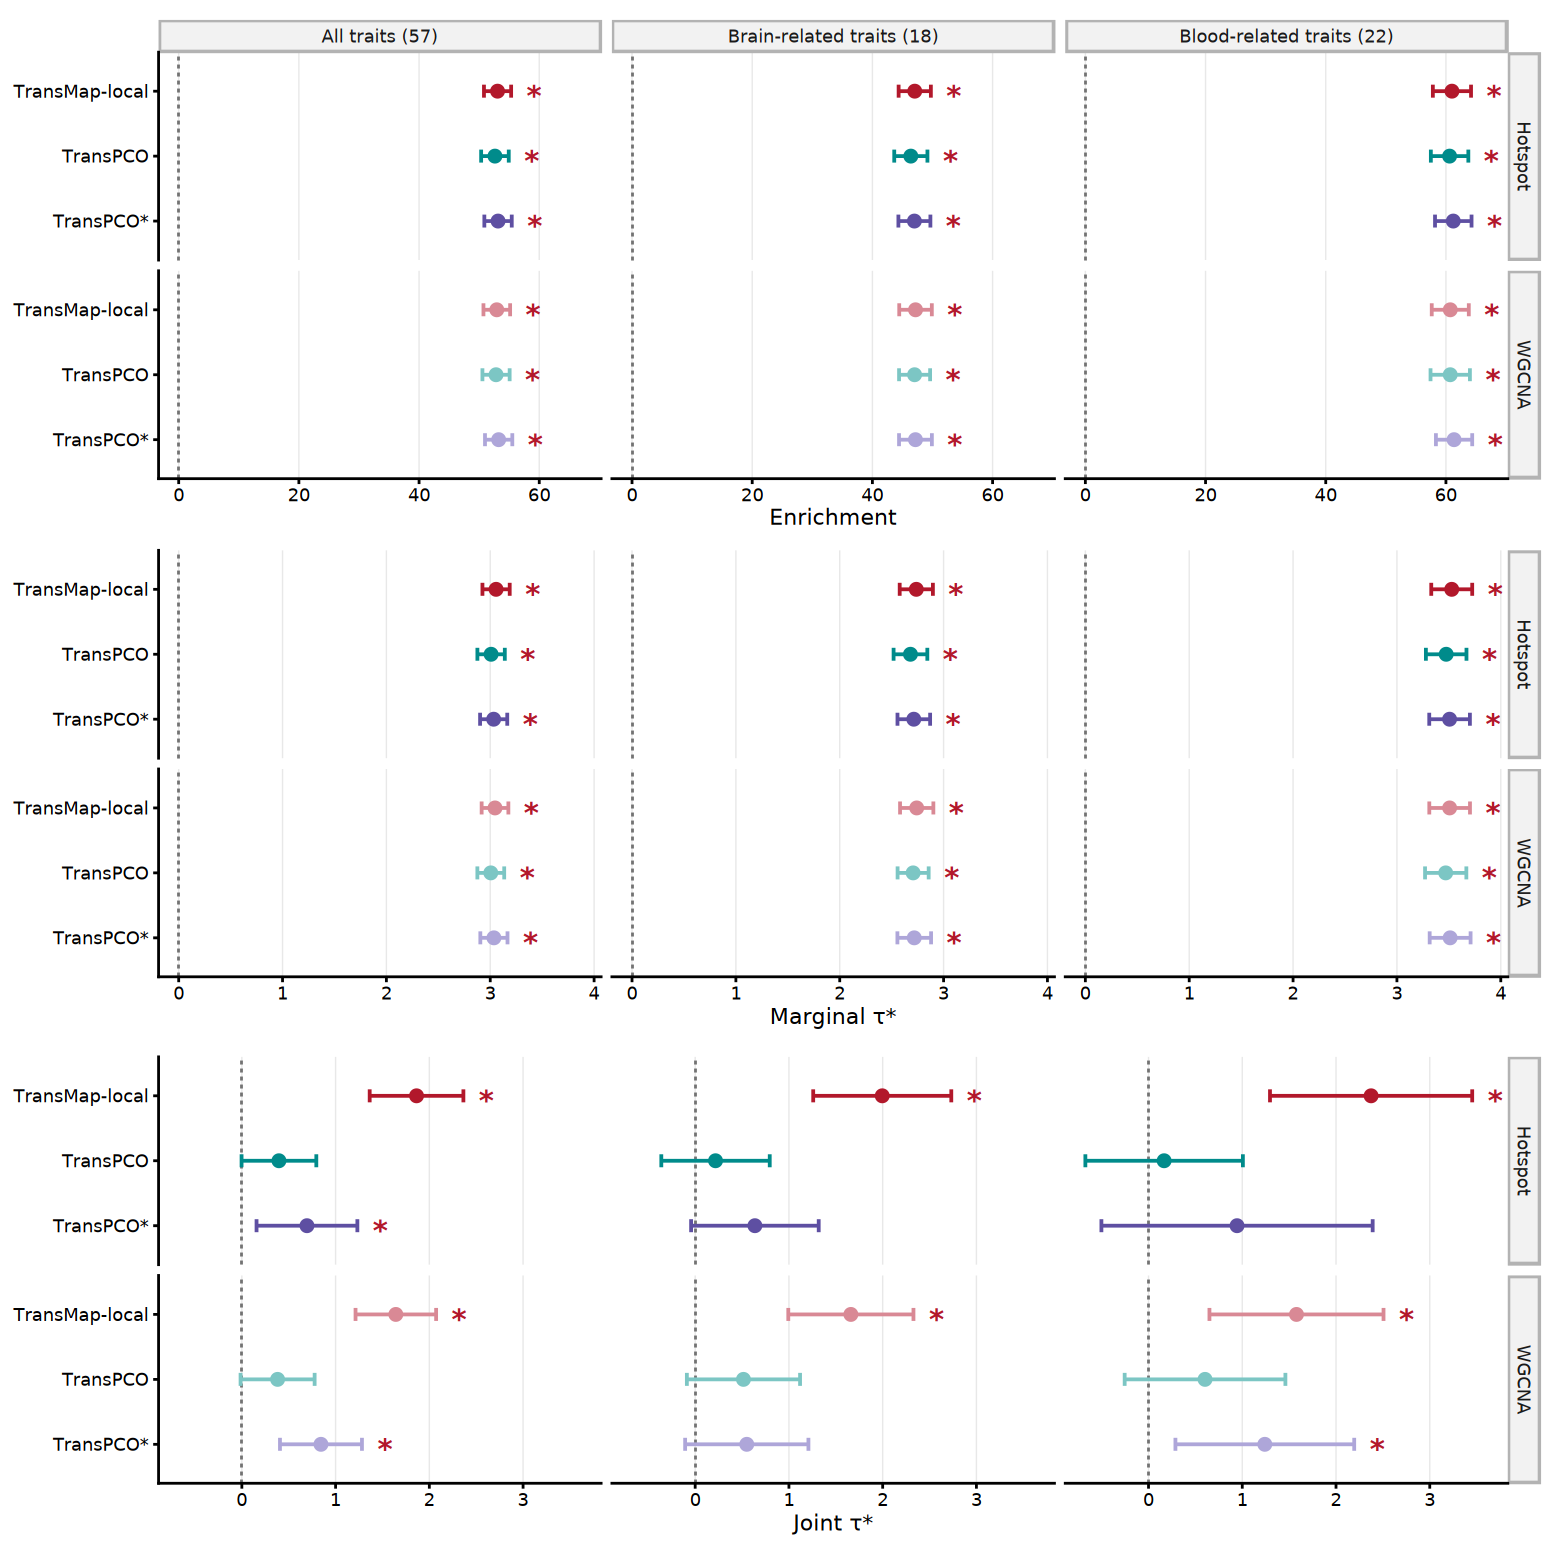

In [2]:
forest_row <- function(d, cols, xlab = NULL, vline = 0, show_strip = TRUE, facet_rows = NULL) {
  d$ci_low <- d$est - 1.9 * d$se; d$ci_high <- d$est + 1.9 * d$se
  d$star <- ifelse(d$pvalue < 0.05 & d$est > 0, "*", "")
  pad <- 0.04 * diff(range(c(d$ci_low, d$ci_high, vline)))
  p <- ggplot(d, aes(y = method, colour = colour_key)) +
    geom_vline(xintercept = vline, linetype = "dashed", colour = "grey45") +
    geom_errorbar(aes(xmin = ci_low, xmax = ci_high), width = 0.2, orientation = "y", linewidth = 0.8) +
    geom_point(aes(x = est), size = 3) +
    geom_text(aes(x = ci_high + pad, label = star), colour = "#B2182B", size = 6, fontface = "bold", hjust = 0, vjust = 0.7) +
    scale_colour_manual(values = cols, guide = "none") +
    scale_y_discrete(limits = rev) +
    labs(x = xlab, y = NULL) +
    theme_classic(base_size = 13) +
    theme(strip.background = element_rect(fill = "grey95", colour = "grey70"),
          panel.grid.major.x = element_line(colour = "grey91", linewidth = 0.3))
  p <- p + if (is.null(facet_rows)) facet_grid(. ~ trait) else facet_grid(reformulate("trait", facet_rows))
  if (!show_strip) p <- p + theme(strip.text.x = element_blank(), strip.background.x = element_blank())
  p
}

hot <- c("TransMap-local" = "#B2182B", "TransPCO" = "#008B8B", "TransPCO*" = "#5E4FA2")
wg  <- c("TransMap-local" = "#D98995", "TransPCO" = "#7CC6C4", "TransPCO*" = "#AEA6D9")
cols <- c(setNames(hot, paste("Hotspot", names(hot))), setNames(wg, paste("WGCNA", names(wg))))
res$colour_key <- paste(res$program_source, res$method)
xl <- list("Enrichment" = "Enrichment", "Marginal tau*" = expression("Marginal " * tau * "*"),
           "Joint tau*" = expression("Joint " * tau * "*"))
rows <- lapply(names(xl), function(m) forest_row(subset(res, metric == m), cols, xlab = xl[[m]],
                                                  show_strip = m == "Enrichment", facet_rows = "program_source"))
options(repr.plot.width = 13, repr.plot.height = 13)
wrap_plots(rows, ncol = 1)